
[1] Caricamento dati S&P 500...
  Training: 239 mesi (2000-02 -> 2019-12)
  Test:     48 mesi (2020-01 -> 2023-12)

[2] Calibrazione parametri sul training set (2000-2019)...
  BS:  mu=0.0527  sigma=0.1649  rho=0.1981
  BS:  mu=0.0527  sigma=0.1649  rho=0.1981
  MJD: mu=0.0518  sigma=0.0668  lam=10.12  m=-0.0183  delta=0.0421
       sigma_J^2=0.020360

  phi_1* BS  = 1.2017
  phi_1* MJD = 1.2810

[3] Calibrazione psi3 iniziale...
  psi3 iniziale (rho^2) = 0.0393
  Ottimizzatore phi: Adam (lr=0.001, beta1=0.9, beta2=0.999)

[4] Training offline su dati reali 2000-2019 (N=20000)...
  Iterazione  2000/20000  phi_1=0.6079  omega=1.4159
  Iterazione  4000/20000  phi_1=0.9262  omega=1.4226
  Iterazione  6000/20000  phi_1=1.0594  omega=1.4276
  Iterazione  8000/20000  phi_1=1.1493  omega=1.4318
  Iterazione 10000/20000  phi_1=1.1363  omega=1.4356
  Iterazione 12000/20000  phi_1=1.1679  omega=1.4389
  Iterazione 14000/20000  phi_1=1.2100  omega=1.4420
  Iterazione 16000/20000  phi_1=1.2836  o

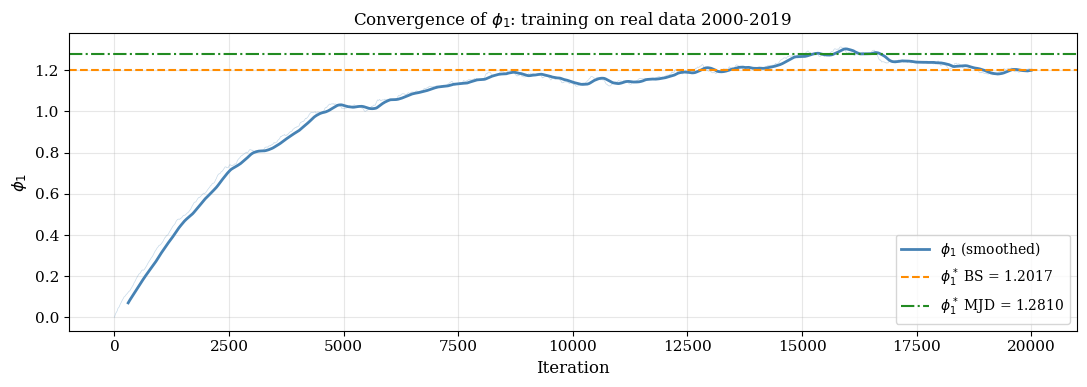


  Figura 1 salvata.


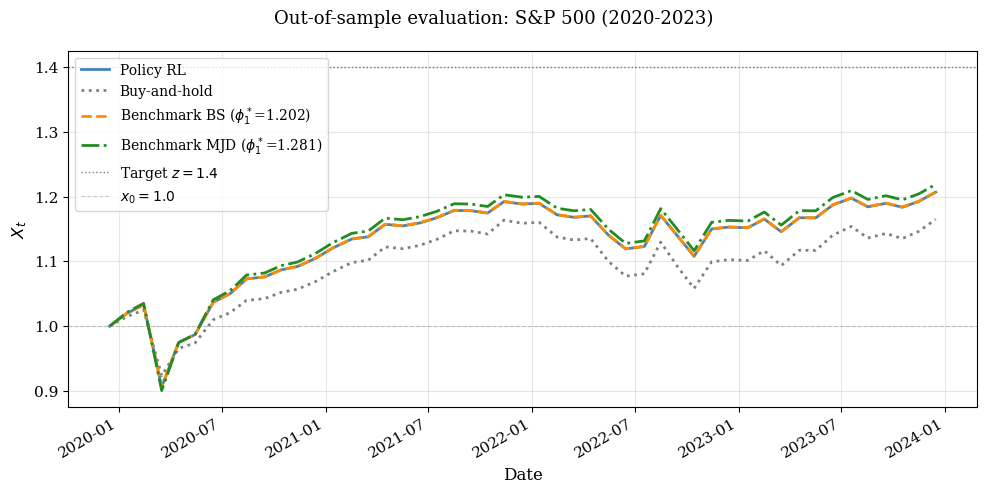

  Figura 2 salvata.


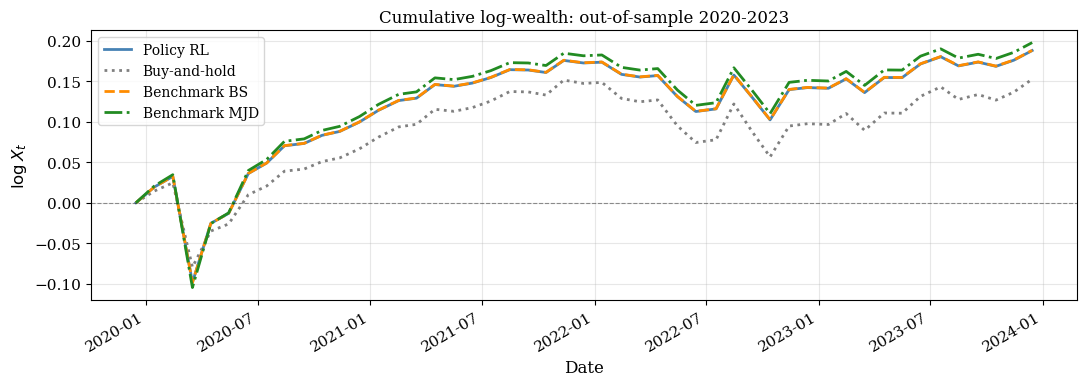

  Figura 3 salvata.

  STATISTICHE OUT-OF-SAMPLE (2020-2023, annualizzate)
  Strategia                            X_T    Ret%    Vol%   Sharpe    MaxDD
  ----------------------------------------------------------------
  Policy RL                         1.2068    4.70    9.25   0.2917  -12.27%
  Buy-and-hold                      1.1649    3.82    8.03   0.2260   -9.89%
  Benchmark BS                      1.2071    4.71    9.27   0.2920  -12.29%
  Benchmark MJD                     1.2187    4.94    9.78   0.3010  -13.01%

  phi_1 appreso (training) = 1.1995
  phi_1* BS                = 1.2017
  phi_1* MJD               = 1.2810

Tutto completato.


In [1]:
"""
mv_backtest.py — Applicazione su Dati Reali S&P 500: Train/Test Split
======================================================================
Struttura:
  TRAINING  (2000-2019): offline q-learning sul simulatore reale S&P 500
                         rendimenti mensili campionati con reimmissione
                         N = 20000 iterazioni, identico a mv_realdata.py
  TEST      (2020-2023): applica la policy appresa ai 4 anni successivi
                         out-of-sample, senza ulteriori aggiornamenti

Confronto nel periodo di test:
  - Policy RL appresa
  - Buy-and-hold (investimento fisso proporzionale a x_0)
  - Benchmark analitico phi_1* calcolato sui dati di training

Output:
  figure_test_wealth.pdf/png   — ricchezza accumulata nel periodo di test
  figure_test_monthly.pdf/png  — rendimenti mensili confrontati
  figure_train_conv.pdf/png    — convergenza di phi_1 nel training

Utilizzo:
  pip install yfinance numpy matplotlib scipy
  python mv_backtest.py
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib as mpl
from scipy.optimize import minimize
from scipy.stats import norm, poisson
from scipy.integrate import quad

np.random.seed(42)

mpl.rcParams.update({
    'font.family':    'serif',
    'font.size':      11,
    'axes.titlesize': 12,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
})

# ─────────────────────────────────────────────────────────────────────────────
# 1.  PARAMETRI GLOBALI
# ─────────────────────────────────────────────────────────────────────────────

R_F    = 0.02
DT     = 1 / 12
T      = 1.0
K      = 12
THETA  = 0.1
Z      = 1.4
X0     = 1.0

N_TRAIN = 20000
BATCH   = 32
ALPHA_PSI   = 0.001
ALPHA_OMEGA = 0.05
DECAY       = 0.51
GRAD_CLIP   = 5.0

# Adam optimizer per phi (nessuna calibrazione manuale richiesta)
ADAM_LR      = 0.001
ADAM_BETA1   = 0.9
ADAM_BETA2   = 0.999
ADAM_EPS     = 1e-8

TRAIN_END = '2019-12-31'
TEST_START = '2020-01-01'
TEST_END   = '2023-12-31'


# ─────────────────────────────────────────────────────────────────────────────
# 2.  DOWNLOAD E PREPROCESSING
# ─────────────────────────────────────────────────────────────────────────────

def load_sp500_split(train_end=TRAIN_END, test_end=TEST_END):
    import yfinance as yf
    data    = yf.download('^GSPC', start='2000-01-01',
                          end=test_end, progress=False)
    prices  = data['Close'].dropna()
    closes  = prices.values.flatten()
    log_ret_daily = np.diff(np.log(closes))
    dates_daily   = prices.index[1:]

    # Aggrega in rendimenti mensili (21 giorni di trading)
    dpm = 21
    n_months = len(log_ret_daily) // dpm
    log_ret_monthly = np.array([
        log_ret_daily[i*dpm:(i+1)*dpm].sum()
        for i in range(n_months)
    ])
    import pandas as pd
    dates_monthly = np.array([
        pd.Timestamp(dates_daily[min((i+1)*dpm - 1, len(dates_daily)-1)])
        for i in range(n_months)
    ])

    # Split train/test
    from datetime import datetime
    cutoff = datetime.strptime(train_end, '%Y-%m-%d')
    # Normalizza i dates a datetime puro (rimuove tzinfo se presente)
    def to_dt(d):
        if hasattr(d, 'to_pydatetime'):
            d = d.to_pydatetime()
        if hasattr(d, 'tzinfo') and d.tzinfo is not None:
            d = d.replace(tzinfo=None)
        return d
    mask_train = np.array([to_dt(d) <= cutoff for d in dates_monthly], dtype=bool)
    mask_test  = ~mask_train

    ret_train   = log_ret_monthly[mask_train]
    ret_test    = log_ret_monthly[mask_test]
    dates_train = dates_monthly[mask_train]
    dates_test  = dates_monthly[mask_test]

    print(f"  Training: {len(ret_train)} mesi "
          f"({dates_train[0].strftime('%Y-%m')} -> "
          f"{dates_train[-1].strftime('%Y-%m')})")
    print(f"  Test:     {len(ret_test)} mesi "
          f"({dates_test[0].strftime('%Y-%m')} -> "
          f"{dates_test[-1].strftime('%Y-%m')})")
    return ret_train, ret_test, dates_train, dates_test


# ─────────────────────────────────────────────────────────────────────────────
# 3.  CALIBRAZIONE PARAMETRI
# ─────────────────────────────────────────────────────────────────────────────

def calibrate_bs(log_ret, r_f=R_F):
    sigma = np.std(log_ret) / np.sqrt(DT)
    mu    = np.mean(log_ret) / DT + 0.5 * sigma**2
    rho   = (mu - r_f) / sigma
    print(f"  BS:  mu={mu:.4f}  sigma={sigma:.4f}  rho={rho:.4f}")
    return dict(mu=mu, sigma=sigma, rho=rho, sJ2=0.)


def calibrate_mjd(log_ret, r_f=R_F):
    def neg_log_lik(params):
        mu, sigma, lam, m, delta = params
        if sigma <= 0 or lam <= 0 or delta <= 0:
            return 1e10
        kappa = np.exp(m + 0.5*delta**2) - 1
        n_max = max(10, int(lam*DT*5 + 20))
        ns    = np.arange(0, n_max+1)
        pn    = poisson.pmf(ns, lam*DT)
        pdf   = np.zeros(len(log_ret))
        for n, p_n in zip(ns, pn):
            if p_n < 1e-15: continue
            mu_n  = (mu - 0.5*sigma**2 - lam*kappa)*DT + n*m
            var_n = sigma**2*DT + n*delta**2
            pdf  += p_n * norm.pdf(log_ret, mu_n, np.sqrt(var_n))
        return -np.sum(np.log(np.maximum(pdf, 1e-300)))

    bs  = calibrate_bs(log_ret, r_f)
    x0  = [bs['mu'], bs['sigma'], 28.0, -0.004, 0.027]
    bds = [(None,None),(1e-4,None),(1e-4,None),(None,None),(1e-4,None)]
    res = minimize(neg_log_lik, x0, method='L-BFGS-B', bounds=bds,
                   options=dict(maxiter=500, ftol=1e-9))
    mu, sigma, lam, m, delta = res.x
    rho   = (mu - r_f) / sigma
    sJ2   = lam*(np.exp(2*m+2*delta**2) - 2*np.exp(m+0.5*delta**2) + 1)
    kappa = np.exp(m + 0.5*delta**2) - 1
    print(f"  MJD: mu={mu:.4f}  sigma={sigma:.4f}  lam={lam:.2f}"
          f"  m={m:.4f}  delta={delta:.4f}")
    print(f"       sigma_J^2={sJ2:.6f}")
    return dict(mu=mu, sigma=sigma, lam=lam, m=m, delta=delta,
                rho=rho, sJ2=sJ2, kappa=kappa)


def phi1_star(params, r_f=R_F):
    sigma = params['sigma']
    rho   = (params['mu'] - r_f) / sigma
    sJ2   = params.get('sJ2', 0.)
    return rho * sigma / (sigma**2 + sJ2)


# ─────────────────────────────────────────────────────────────────────────────
# 4.  SIMULATORE SUI DATI REALI
# ─────────────────────────────────────────────────────────────────────────────

class RealDataSimulator:
    """
    Simulatore bootstrap: campiona rendimenti mensili reali con reimmissione.
    Semplice e robusto. La dipendenza temporale viene ignorata — questo e'
    una limitazione metodologica discussa nella tesi (Appendice B).
    """
    def __init__(self, log_ret_monthly):
        self.returns = log_ret_monthly

    def simulate_trajectory(self, n=12):
        return np.random.choice(self.returns, size=n, replace=True)

    def step(self, x, a):
        r = np.random.choice(self.returns)
        return x + a * (np.exp(r) - 1 - R_F * DT)


# ─────────────────────────────────────────────────────────────────────────────
# 5.  PARAMETRIZZAZIONI
# ─────────────────────────────────────────────────────────────────────────────

class MVModel:
    def __init__(self, psi3_init=0.):
        self.psi   = np.array([0., 0., psi3_init])
        self.phi   = np.zeros(3)
        self.omega = Z

    def _c(self, t):
        return np.exp(np.clip(-self.phi[1] - self.phi[2]*(T-t), -30, 30))

    def J(self, t, x):
        p = self.psi; o = self.omega
        e = np.exp(np.clip(-p[2]*(T-t), -30, 30))
        return (x-o)**2*e + p[1]*(t**2-T**2) + p[0]*(t-T) - (o-Z)**2

    def grad_J(self, t, x):
        p = self.psi; o = self.omega
        e = np.exp(np.clip(-p[2]*(T-t), -30, 30))
        return np.array([t-T, t**2-T**2, -(T-t)*(x-o)**2*e])

    def q(self, t, x, a):
        p = self.phi; o = self.omega; c = self._c(t)
        return (-c/2*(a + p[0]*(x-o))**2
                - THETA/2*(np.log(2*np.pi*THETA) + p[1] + p[2]*(T-t)))

    def grad_q(self, t, x, a):
        p = self.phi; o = self.omega; c = self._c(t); r = a + p[0]*(x-o)
        return np.array([
            c*r*(x-o),
            0.5*c*r**2 - THETA/2,
            (T-t)*0.5*c*r**2 - THETA*(T-t)/2
        ])

    def sample_action(self, t, x):
        mu  = -self.phi[0]*(x - self.omega)
        var = max(THETA*self._c(t), 1e-8)
        return float(np.random.normal(mu, np.sqrt(var)))

    def mean_action(self, t, x):
        return -self.phi[0]*(x - self.omega)


# ─────────────────────────────────────────────────────────────────────────────
# 6.  TRAINING OFFLINE
# ─────────────────────────────────────────────────────────────────────────────

def calibrate_alpha_phi(bs_params, ret_train, n_samples=300):
    phi1t  = phi1_star(bs_params)
    psi3_t = (bs_params['mu'] - R_F)**2 / bs_params['sigma']**2
    sim    = RealDataSimulator(ret_train)
    grads  = []
    for _ in range(n_samples):
        x = X0; g = 0.; o = Z
        for k in range(K):
            t    = k * DT
            mu_a = -phi1t*(x-o)
            a    = np.random.normal(mu_a, np.sqrt(THETA))
            xn   = sim.step(x, a)
            if not np.isfinite(xn): xn = x
            Jn = (xn-o)**2 * np.exp(-psi3_t*(T-(t+DT)))
            Jc = (x -o)**2 * np.exp(-psi3_t*(T-t))
            qc = -0.5*(a+phi1t*(x-o))**2 - THETA/2*np.log(2*np.pi*THETA)
            td = Jn - Jc - qc*DT
            g += (a+phi1t*(x-o))*(x-o)*td/K
            x  = xn
        grads.append(g)
    grad_std = np.std(grads)
    I_total  = quad(lambda x: x**(-DECAY), 1, N_TRAIN)[0]
    alpha    = phi1t / (grad_std * I_total) * 1.5
    print(f"  Scala gradiente: std={grad_std:.6f}")
    print(f"  alpha_phi calibrato: {alpha:.2f}")
    return alpha, psi3_t


def offline_training(sim, psi3_init):
    """
    Training offline con:
    - Bootstrap resampling per generare traiettorie (campionamento i.i.d. dai
      rendimenti storici, approccio model-free; cfr. Huang-Jia-Zhou 2022)
    - Ottimizzatore Adam per phi (nessuna calibrazione manuale di alpha_phi)
    - Decay standard j^{-0.51} per psi e omega
    """
    model    = MVModel(psi3_init=psi3_init)
    phi1_hist = np.zeros(N_TRAIN)

    # Stato Adam per phi
    m_phi = np.zeros(3)   # primo momento
    v_phi = np.zeros(3)   # secondo momento
    adam_step = 0

    for j in range(1, N_TRAIN+1):
        lr    = j**(-DECAY)
        d_psi = np.zeros(3); d_phi = np.zeros(3); d_omega = 0.

        for _ in range(BATCH):
            # Genera traiettoria con GARCH (o bootstrap se GARCH non disponibile)
            if hasattr(sim, 'simulate_trajectory'):
                rets = sim.simulate_trajectory(K)
            else:
                rets = np.random.choice(sim.returns, size=K, replace=True)

            xs   = np.zeros(K+1); acts = np.zeros(K)
            xs[0] = X0
            for k in range(K):
                acts[k] = model.sample_action(k*DT, xs[k])
                xn = xs[k] + acts[k] * (np.exp(rets[k]) - 1 - R_F*DT)
                xs[k+1] = xn if np.isfinite(xn) else xs[k]
            for k in range(K):
                td = (model.J((k+1)*DT, xs[k+1])
                      - model.J(k*DT, xs[k])
                      - model.q(k*DT, xs[k], acts[k])*DT)
                if np.isfinite(td):
                    d_psi += model.grad_J(k*DT, xs[k]) * td / K
                    d_phi += model.grad_q(k*DT, xs[k], acts[k]) * td / K
            d_omega += xs[K] - Z

        # Gradient clipping
        for g in [d_psi, d_phi]:
            n_norm = np.linalg.norm(g)
            if n_norm > GRAD_CLIP * BATCH:
                g *= GRAD_CLIP * BATCH / n_norm

        # Aggiornamento psi: SGD con decay
        model.psi += lr * ALPHA_PSI * d_psi / BATCH

        # Aggiornamento phi: Adam (nessun decay esterno, Adam gestisce la scala)
        adam_step += 1
        grad_phi   = d_phi / BATCH
        m_phi      = ADAM_BETA1 * m_phi + (1 - ADAM_BETA1) * grad_phi
        v_phi      = ADAM_BETA2 * v_phi + (1 - ADAM_BETA2) * grad_phi**2
        m_hat      = m_phi / (1 - ADAM_BETA1**adam_step)
        v_hat      = v_phi / (1 - ADAM_BETA2**adam_step)
        model.phi += ADAM_LR * m_hat / (np.sqrt(v_hat) + ADAM_EPS)
        model.phi[1] = np.clip(model.phi[1], -10, 10)
        model.phi[2] = np.clip(model.phi[2], -10, 10)

        # Aggiornamento omega: SGD con decay
        if j % 10 == 0:
            model.omega -= lr * ALPHA_OMEGA * d_omega / (BATCH * 10)

        phi1_hist[j-1] = model.phi[0]
        if j % 2000 == 0:
            print(f"  Iterazione {j:5d}/{N_TRAIN}  phi_1={model.phi[0]:.4f}"
                  f"  omega={model.omega:.4f}")

    return model, phi1_hist


# ─────────────────────────────────────────────────────────────────────────────
# 7.  VALUTAZIONE OUT-OF-SAMPLE
# ─────────────────────────────────────────────────────────────────────────────

def evaluate_test(model, ret_test, dates_test, phi1_bs, phi1_mjd):
    """
    Applica la policy appresa ai rendimenti mensili reali del periodo di test.
    Confronta con:
      - Buy-and-hold: investe sempre la stessa frazione fissa (phi1_bs * (X0-omega))
      - Benchmark analitico: usa phi1* calcolato sui dati di training
    """
    n_test    = len(ret_test)
    wealth_rl  = np.zeros(n_test + 1); wealth_rl[0]  = X0
    wealth_bh  = np.zeros(n_test + 1); wealth_bh[0]  = X0
    wealth_bs  = np.zeros(n_test + 1); wealth_bs[0]  = X0
    wealth_mjd = np.zeros(n_test + 1); wealth_mjd[0] = X0

    # Buy-and-hold: investe una quota fissa = (Z - X0) ogni mese
    a_bh = Z - X0   # ~0.4

    for k, r in enumerate(ret_test):
        t   = (k % K) * DT
        ret = np.exp(r) - 1 - R_F * DT

        # RL policy
        a_rl = model.mean_action(t, wealth_rl[k])
        wealth_rl[k+1] = wealth_rl[k] + a_rl * ret

        # Buy-and-hold
        wealth_bh[k+1] = wealth_bh[k] + a_bh * ret

        # Benchmark BS
        a_bs = -phi1_bs * (wealth_bs[k] - model.omega)
        wealth_bs[k+1] = wealth_bs[k] + a_bs * ret

        # Benchmark MJD
        a_mj = -phi1_mjd * (wealth_mjd[k] - model.omega)
        wealth_mjd[k+1] = wealth_mjd[k] + a_mj * ret

    return wealth_rl, wealth_bh, wealth_bs, wealth_mjd


# ─────────────────────────────────────────────────────────────────────────────
# 8.  MAIN
# ─────────────────────────────────────────────────────────────────────────────

if __name__ == '__main__':

    print("\n[1] Caricamento dati S&P 500...")
    ret_train, ret_test, dates_train, dates_test = load_sp500_split()

    print("\n[2] Calibrazione parametri sul training set (2000-2019)...")
    bs_params  = calibrate_bs(ret_train)
    mjd_params = calibrate_mjd(ret_train)
    PHI1_BS    = phi1_star(bs_params)
    PHI1_MJD   = phi1_star(mjd_params)
    print(f"\n  phi_1* BS  = {PHI1_BS:.4f}")
    print(f"  phi_1* MJD = {PHI1_MJD:.4f}")

    print("\n[3] Calibrazione psi3 iniziale...")
    rho_train = (bs_params['mu'] - R_F) / bs_params['sigma']
    psi3_init = rho_train**2
    print(f"  psi3 iniziale (rho^2) = {psi3_init:.4f}")
    print(f"  Ottimizzatore phi: Adam (lr={ADAM_LR}, beta1={ADAM_BETA1}, beta2={ADAM_BETA2})")

    print(f"\n[4] Training offline su dati reali 2000-2019 (N={N_TRAIN})...")
    sim_real = RealDataSimulator(ret_train)
    model, phi1_hist = offline_training(sim_real, psi3_init)

    print(f"\n  phi_1 finale = {model.phi[0]:.4f}")
    print(f"  phi_1* BS    = {PHI1_BS:.4f}")
    print(f"  phi_1* MJD   = {PHI1_MJD:.4f}")

    print("\n[5] Valutazione out-of-sample (2020-2023)...")
    wealth_rl, wealth_bh, wealth_bs, wealth_mjd = evaluate_test(
        model, ret_test, dates_test, PHI1_BS, PHI1_MJD)

    # date per i grafici del test (mensili)
    from datetime import timedelta
    test_dates = np.concatenate([
        [dates_test[0] - timedelta(days=30)], dates_test])

    print(f"\n  Ricchezza finale (2020-2023):")
    print(f"    Policy RL:         {wealth_rl[-1]:.4f}")
    print(f"    Buy-and-hold:      {wealth_bh[-1]:.4f}")
    print(f"    Benchmark BS:      {wealth_bs[-1]:.4f}")
    print(f"    Benchmark MJD:     {wealth_mjd[-1]:.4f}")

    # ── Figure ───────────────────────────────────────────────────────────────

    # Figura 1 — Convergenza phi_1 nel training
    fig, ax = plt.subplots(figsize=(11, 4))
    w  = 300
    ph = phi1_hist
    sm = np.convolve(ph, np.ones(w)/w, mode='valid')
    ax.plot(ph, color='steelblue', lw=0.5, alpha=0.3)
    ax.plot(range(w-1, len(ph)), sm,
            color='steelblue', lw=2.0, label=r'$\phi_1$ (smoothed)')
    ax.axhline(PHI1_BS,  color='darkorange',  lw=1.5, ls='--',
               label=fr'$\phi_1^*$ BS = {PHI1_BS:.4f}')
    ax.axhline(PHI1_MJD, color='forestgreen', lw=1.5, ls='-.',
               label=fr'$\phi_1^*$ MJD = {PHI1_MJD:.4f}')
    ax.set_title(r'Convergence of $\phi_1$: training on real data 2000-2019',
                 fontsize=12)
    ax.set_xlabel('Iteration'); ax.set_ylabel(r'$\phi_1$', fontsize=12)
    ax.legend(); ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('convergenza_RL.pdf', dpi=150, bbox_inches='tight')
    plt.savefig('convergenza_RL.png', dpi=150, bbox_inches='tight')
    plt.show(); plt.close()
    print("\n  Figura 1 salvata.")

    # Figura 2 — Ricchezza out-of-sample 2020-2023
    fig, ax = plt.subplots(figsize=(10, 5))
    fig.suptitle('Out-of-sample evaluation: S&P 500 (2020-2023)', fontsize=13)

    entries = [
        (wealth_rl,  'steelblue',   '-',  'Policy RL'),
        (wealth_bh,  'gray',        ':',  'Buy-and-hold'),
        (wealth_bs,  'darkorange',  '--', fr'Benchmark BS ($\phi_1^*$={PHI1_BS:.3f})'),
        (wealth_mjd, 'forestgreen', '-.', fr'Benchmark MJD ($\phi_1^*$={PHI1_MJD:.3f})'),
    ]

    for w_arr, col, ls, lbl in entries:
        ax.plot(test_dates, w_arr, color=col, lw=2.0, ls=ls, label=lbl)
    ax.axhline(Z, color='black', lw=1, ls=':', alpha=0.5,
               label=f'Target $z={Z}$')
    ax.axhline(X0, color='gray', lw=0.8, ls='--', alpha=0.4,
               label=f'$x_0={X0}$')
    ax.set_xlabel('Date'); ax.set_ylabel(r'$X_t$', fontsize=12)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha='right')
    ax.legend(fontsize=10); ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('rl_out_of_sample.pdf', dpi=150, bbox_inches='tight')
    plt.savefig('rl_out_of_sample.png', dpi=150, bbox_inches='tight')
    plt.show(); plt.close()
    print("  Figura 2 salvata.")

    # Figura 3 — Rendimenti mensili cumulativi nel test
    fig, ax = plt.subplots(figsize=(11, 4))
    cum_rl  = np.log(np.maximum(wealth_rl,  1e-6))
    cum_bh  = np.log(np.maximum(wealth_bh,  1e-6))
    cum_bs  = np.log(np.maximum(wealth_bs,  1e-6))
    cum_mjd = np.log(np.maximum(wealth_mjd, 1e-6))

    for cum, col, ls, lbl in [
        (cum_rl,  'steelblue',  '-',  'Policy RL'),
        (cum_bh,  'gray',       ':',  'Buy-and-hold'),
        (cum_bs,  'darkorange', '--', 'Benchmark BS'),
        (cum_mjd, 'forestgreen','-.', 'Benchmark MJD'),
    ]:
        ax.plot(test_dates, cum, color=col, lw=2.0, ls=ls, label=lbl)

    ax.axhline(0, color='black', lw=0.8, ls='--', alpha=0.4)
    ax.set_title('Cumulative log-wealth: out-of-sample 2020-2023',
                 fontsize=12)
    ax.set_xlabel('Date'); ax.set_ylabel(r'$\log X_t$', fontsize=12)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha='right')
    ax.legend(); ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('figure_test_logwealth.pdf', dpi=150, bbox_inches='tight')
    plt.savefig('figure_test_logwealth.png', dpi=150, bbox_inches='tight')
    plt.show(); plt.close()
    print("  Figura 3 salvata.")

    # ── Statistiche finali ───────────────────────────────────────────────────
    def stats(w):
        ret = np.diff(np.log(np.maximum(w, 1e-6)))
        ann_ret = ret.mean() * 12
        ann_vol = ret.std() * np.sqrt(12)
        sharpe  = (ann_ret - R_F) / ann_vol if ann_vol > 0 else np.nan
        dd      = np.min(w / np.maximum.accumulate(w)) - 1
        return w[-1], ann_ret, ann_vol, sharpe, dd

    print("\n" + "="*68)
    print("  STATISTICHE OUT-OF-SAMPLE (2020-2023, annualizzate)")
    print("="*68)
    print(f"  {'Strategia':<32} {'X_T':>7} {'Ret%':>7}"
          f" {'Vol%':>7} {'Sharpe':>8} {'MaxDD':>8}")
    print(f"  {'-'*64}")
    for label, w_arr in [
        ('Policy RL',          wealth_rl),
        ('Buy-and-hold',       wealth_bh),
        (f'Benchmark BS',      wealth_bs),
        (f'Benchmark MJD',     wealth_mjd),
    ]:
        xt, ar, av, sh, dd = stats(w_arr)
        print(f"  {label:<32} {xt:>7.4f} {ar*100:>7.2f}"
              f" {av*100:>7.2f} {sh:>8.4f} {dd:>8.2%}")
    print("="*68)
    print(f"\n  phi_1 appreso (training) = {model.phi[0]:.4f}")
    print(f"  phi_1* BS                = {PHI1_BS:.4f}")
    print(f"  phi_1* MJD               = {PHI1_MJD:.4f}")
    print("\nTutto completato.")